# ESCM 2.0 — Controlled persistence versus replacement (Notebook 15)

## Question

Notebook 14 suggested synaptic depression might support edge replacement, but its metric classified a pixel as active after **one spike** and its old/new edges were separated by five pixels—outside the radius of direct lateral inhibition (four pixels). This follow-up corrects both problems **without changing the underlying neuron or synapse equations**.

We test three distinct claims rather than combine them in one score:

1. **Persistence:** Does an edge continue to spike long after its last camera event?
2. **Suppression versus spontaneous fading:** Does introducing a new edge *reduce* old-edge firing relative to a matched old-only control?
3. **Successful replacement:** Does the new edge sustain recurrent activity, rather than producing a short transient that disappears on its own?

A fourth, simultaneous-input control checks whether the same mechanism preserves two spatial patterns or collapses into winner-take-all suppression.

We retain Notebook 14's model equations, synaptic depression rule, adaptation, and variants. The **only circuit manipulation** is making inhibitory strengths explicit sweep variables; the geometry is corrected so that the two edges can interact. The engineered gate remains a comparator, not a recommended biological mechanism.

## 1. Parameters and geometry

The old edge lies at x=2 and the new edge at x=5 (five neurons each, y=1–5). Their minimum separation is three pixels. Thus direct inhibition (radius four) can connect the edges, while local excitation (radius 1.5) cannot. They occupy distinct neurons.

The original input pattern is unchanged: three camera pulses per pixel, at 2, 4, 6 ms for the old edge, and at 35, 37, 39 ms for the new edge. The run extends to 100 ms, giving 61 ms after the final new-edge input. We keep parameter values from notebook 14 until the targeted inhibitory-strength experiments.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import brian2 as b2

b2.prefs.codegen.target = "numpy"

width, height = 10, 7
N = width * height
xy = np.column_stack((np.arange(N) % width, np.arange(N) // width))
old_edge = np.flatnonzero((xy[:, 0] == 2) & (xy[:, 1] >= 1) & (xy[:, 1] <= 5))
new_edge = np.flatnonzero((xy[:, 0] == 5) & (xy[:, 1] >= 1) & (xy[:, 1] <= 5))
other = np.setdiff1d(np.arange(N), np.r_[old_edge, new_edge])

# Times in ms, dimensionless current amplitudes.
total_ms = 100.0
input_gain, v_threshold = 6.0, 1.0
self_weight, lateral_gain, inhibitory_gain = 8.0, 1.7, 2.2
cap, recovery_ms, depression_use = 24.0, 60.0, 0.3
adapt_jump = 0.35
refractory_ms = 2.0

# Include single mechanisms, controlled combinations, and one-at-a-time full-model ablations.
variants = {
    "assignment":              dict(self_rule="assign"),
    "additive":                dict(self_rule="add"),
    "additive + refractory":   dict(self_rule="add", refractory=True),
    "saturating":              dict(self_rule="saturate"),
    "depression + refractory": dict(self_rule="depress", refractory=True),
    "adaptation + refractory": dict(self_rule="add", refractory=True, adaptation=True),
    "lateral inhibition":      dict(self_rule="add", refractory=True, inhibition="direct"),
    "local E + broad I":       dict(self_rule="add", refractory=True, local_e=True, inhibition="direct"),
    "inhibitory interneurons":  dict(self_rule="add", refractory=True, local_e=True, inhibition="interneuron"),
    "full natural circuit":    dict(self_rule="depress", refractory=True, adaptation=True,
                                    local_e=True, inhibition="interneuron"),
    "full minus depression":   dict(self_rule="add", refractory=True, adaptation=True,
                                    local_e=True, inhibition="interneuron"),
    "full minus adaptation":   dict(self_rule="depress", refractory=True,
                                    local_e=True, inhibition="interneuron"),
    "full minus local E":      dict(self_rule="depress", refractory=True, adaptation=True,
                                    inhibition="interneuron"),
    "full minus inhibition":   dict(self_rule="depress", refractory=True, adaptation=True,
                                    local_e=True),
    "full minus refractory":   dict(self_rule="depress", adaptation=True,
                                    local_e=True, inhibition="interneuron"),
    "engineered P gate":       dict(self_rule="assign", inhibition="direct", gate=True),
}
# The two edges are three pixels apart: within the existing inhibitory radius (4),
# but outside local excitation radius (1.5).
old_new_distance = np.min(np.linalg.norm(xy[old_edge, None, :] - xy[None, new_edge, :], axis=2))
assert 1.5 < old_new_distance <= 4.0
assert set(old_edge).isdisjoint(new_edge)
print(f"Grid: {width} x {height}; old/new separation = {old_new_distance:g} pixels")
print("Brian2", b2.__version__, "NumPy", np.__version__)

/home/bmaacaron-iit.local/.virtualenvs/event-scm/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Grid: 10 x 7; old/new separation = 3 pixels
Brian2 2.10.1 NumPy 2.5.4


## 2. Matched camera-input controls

- **Static:** old edge receives input; no new edge arrives.
- **New only:** new edge receives input at 35–39 ms, with no older activity.
- **Replacement:** old edge first, new edge second. The difference from *static* measures the effect of the second input on old-edge activity. The difference from *new only* tests whether the old representation interferes with the new one.
- **Simultaneous:** both edges receive input at 2–6 ms; probes pattern coexistence.

No simulation starts with a privileged winning neuron or a manually reset state. Both representations see the same input strength and temporal pulse structure.

In [2]:
def stimulus(protocol):
    ids, times = [], []
    bursts = [((old_edge[len(old_edge)//2],), (2., 4., 6.))] if protocol == "single" else []
    if protocol in ("static", "replacement", "simultaneous"):
        bursts.append((old_edge, (2., 4., 6.)))
    if protocol == "new_only":
        bursts.append((new_edge, (35., 37., 39.)))
    if protocol == "replacement":
        bursts.append((new_edge, (35., 37., 39.)))
    elif protocol == "simultaneous":
        bursts.append((new_edge, (2., 4., 6.)))
    for pixels, ticks in bursts:
        for t in ticks:
            for pixel in pixels:
                ids.append(int(pixel))
                times.append(t)
    order = np.argsort(times, kind="stable")
    return np.asarray(ids, dtype=int)[order], np.asarray(times)[order]

for p in ("single", "static", "new_only", "replacement", "simultaneous"):
    ids, ts = stimulus(p)
    print(f"{p:12s}: {len(ids):2d} camera events; first={ts.min():g} ms, last={ts.max():g} ms")

single      :  3 camera events; first=2 ms, last=6 ms
static      : 15 camera events; first=2 ms, last=6 ms
new_only    : 15 camera events; first=35 ms, last=39 ms
replacement : 30 camera events; first=2 ms, last=39 ms
simultaneous: 30 camera events; first=2 ms, last=6 ms


## 3. Unmodified dynamics with adjustable inhibition

We reuse notebook 14's simulation code: LIF membrane, external current, autaptic rule (assignment, additive, saturating or synaptic depression), optional refractory/adaptation, optional lateral excitation, and either direct inhibition or explicit inhibitory interneurons. The original engineered persistence gate is retained as a control.

Only two additional arguments are introduced: `inhibition_strength` (the amplitude of inhibitory connections) and `drive_strength` (the excitatory recruitment of inhibitory interneurons). There is **no per-protocol parameter adjustment**. Identical settings are used for static, new-only, replacement, and simultaneous trials.

In [3]:
def simulate(config, protocol="replacement", dt_ms=0.1, record=False,
             inhibition_strength=None, drive_strength=12.0):
    b2.start_scope()
    b2.defaultclock.dt = dt_ms * b2.ms
    stim_ids, stim_times = stimulus(protocol)
    inhibition_strength = inhibitory_gain if inhibition_strength is None else inhibition_strength
    params = dict(
        tm=10*b2.ms, tx=3*b2.ms, te=5*b2.ms, ti=12*b2.ms,
        ta=40*b2.ms, tr=recovery_ms*b2.ms,
        v_threshold=v_threshold, input_gain=input_gain,
        self_weight=self_weight, cap=cap, U=depression_use,
        adapt_jump=adapt_jump if config.get("adaptation") else 0.0,
        drive_gain=drive_strength,
    )
    gating = config.get("gate", False)
    factor = "P*(Iexc - Iinh)" if gating else "Iexc - Iinh"
    eqs = f"""
    dv/dt = (-v + Iext + {factor} - A)/tm : 1
    dIext/dt = -Iext/tx : 1
    dIexc/dt = -Iexc/te : 1
    dIinh/dt = -Iinh/ti : 1
    dA/dt = -A/ta : 1
    """ + ("P : integer\n" if gating else "")
    if gating:
        events = {"P_ON": "v > v_threshold",
                  "P_OFF": "timestep(t-lastspike, dt) > timestep(dt, dt) and v <= v_threshold"}
        neurons = b2.NeuronGroup(N, eqs, threshold="v > v_threshold",
            reset="v = 0; A += adapt_jump", method="exact", events=events,
            refractory=refractory_ms*b2.ms if config.get("refractory") else 0*b2.ms,
            namespace=params)
        neurons.set_event_schedule("P_ON", when="after_thresholds")
        neurons.run_on_event("P_ON", "P = 1", when="after_thresholds")
        neurons.set_event_schedule("P_OFF", when="groups")
        neurons.run_on_event("P_OFF", "P = 0", when="groups")
        neurons.P = 0
    else:
        neurons = b2.NeuronGroup(N, eqs, threshold="v > v_threshold",
            reset="v = 0; A += adapt_jump", method="exact",
            refractory=refractory_ms*b2.ms if config.get("refractory") else 0*b2.ms,
            namespace=params)
    neurons.v = neurons.Iext = neurons.Iexc = neurons.Iinh = neurons.A = 0
    camera = b2.SpikeGeneratorGroup(N, stim_ids, stim_times*b2.ms)
    feed = b2.Synapses(camera, neurons, on_pre="Iext_post += input_gain", namespace=params)
    feed.connect(j="i")
    objects = [neurons, camera, feed]

    rule = config["self_rule"]
    if rule == "assign":
        update = "Iexc_post = self_weight"
        syn_model = ""
    elif rule == "add":
        update = "Iexc_post += self_weight"
        syn_model = ""
    elif rule == "saturate":
        update = "Iexc_post += self_weight*(1-Iexc_post/cap)"
        syn_model = ""
    else:
        update = "Iexc_post += self_weight*R; R *= (1-U)"
        syn_model = "dR/dt = (1-R)/tr : 1 (clock-driven)"
    self_syn = b2.Synapses(neurons, neurons, model=syn_model, on_pre=update,
                           namespace=params)
    self_syn.connect(i=np.arange(N), j=np.arange(N))
    if rule == "depress":
        self_syn.R = 1
    objects.append(self_syn)

    # Euclidean pixel distance: local cooperative excitation and broader inhibition.
    dx = xy[:, None, 0] - xy[None, :, 0]
    dy = xy[:, None, 1] - xy[None, :, 1]
    distance = np.sqrt(dx*dx + dy*dy)
    if config.get("local_e"):
        src, dst = np.where((distance > 0) & (distance <= 1.5))
        weights = lateral_gain*np.exp(-distance[src, dst]**2/(2*0.85**2))
        if rule == "depress":
            lat = b2.Synapses(neurons, neurons,
                model="w : 1\ndR/dt = (1-R)/tr : 1 (clock-driven)",
                on_pre="Iexc_post += w*R; R *= (1-U)", namespace=params)
        else:
            lat = b2.Synapses(neurons, neurons, model="w : 1",
                              on_pre="Iexc_post += w", namespace=params)
        lat.connect(i=src, j=dst)
        lat.w = weights
        if rule == "depress":
            lat.R = 1
        objects.append(lat)

    inhibitory_mode = config.get("inhibition")
    if inhibitory_mode == "direct":
        src, dst = np.where((distance > 0) & (distance <= 4.0))
        lateral_inh = b2.Synapses(neurons, neurons, model="w : 1",
                                  on_pre="Iinh_post += w")
        lateral_inh.connect(i=src, j=dst)
        lateral_inh.w = inhibition_strength*np.exp(-distance[src, dst]**2/(2*2.5**2))
        objects.append(lateral_inh)
    elif inhibitory_mode == "interneuron":
        # One inhibitory LIF per pixel. An excitatory spike excites its corresponding
        # interneuron, which then inhibits a broader spatial neighborhood.
        inhibitory_cells = b2.NeuronGroup(N, """
            dvi/dt = (-vi + drive)/(7*ms) : 1
            ddrive/dt = -drive/(3*ms) : 1
            """, threshold="vi > 1", reset="vi = 0",
            refractory=2*b2.ms, method="exact")
        inhibitory_cells.vi = inhibitory_cells.drive = 0
        recruit = b2.Synapses(neurons, inhibitory_cells,
                              on_pre="drive_post += drive_gain", namespace=params)
        recruit.connect(j="i")
        src, dst = np.where(distance <= 4.0)
        suppress = b2.Synapses(inhibitory_cells, neurons, model="w : 1",
                               on_pre="Iinh_post += w")
        suppress.connect(i=src, j=dst)
        suppress.w = inhibition_strength*np.exp(-distance[src, dst]**2/(2*2.5**2))
        objects.extend([inhibitory_cells, recruit, suppress])

    output = b2.SpikeMonitor(neurons)
    objects.append(output)
    if record:
        states = b2.StateMonitor(neurons, ["v", "Iexc", "Iinh", "A"],
                                 record=[int(old_edge[2]), int(new_edge[2])], when="end")
        objects.append(states)
    b2.Network(*objects).run(total_ms*b2.ms)
    times = np.asarray(output.t/b2.ms)
    ids = np.asarray(output.i, dtype=int)
    result = dict(t=times, i=ids)
    if record:
        result["state_times"] = np.asarray(states.t/b2.ms)
        result["states"] = {x: np.asarray(getattr(states, x)).copy()
                             for x in ("v", "Iexc", "Iinh", "A")}
        assert all(np.isfinite(x).all() for x in result["states"].values())
    return result

## 4. Quantify sustained firing, not merely one spike

For a set of five edge pixels, compute the output rate in each post-input window. For every edge also report:

- **Mean population rate (Hz/neuron):** total output spikes divided by five neurons and window duration.
- **Fraction with at least two spikes:** rejects single transient outputs from a persistence claim.
- **Fraction active in both late windows:** checks whether activity is present throughout the late period rather than only briefly after input.

We examine **50–65 ms**, **65–80 ms**, and **80–100 ms**, all after the last new-edge input at 39 ms. The latter two windows are our persistence evidence. In the static control, the old edge has received no camera input since 6 ms.

Competition is defined *counterfactually*:

\[
\Delta r_{old}=r_{old}^{replacement}-r_{old}^{static},
\qquad
\Delta r_{new}=r_{new}^{replacement}-r_{new}^{new-only}.
\]

Negative \(\Delta r_{old}\) indicates new-input-dependent suppression, not merely spontaneous decay. Positive persistent firing of the new edge is required separately. A negative old-edge difference alone **does not** establish successful replacement.

In [4]:
windows = ((50,65), (65,80), (80,100))

def edge_metrics(run, edge, a, b):
    ids = run["i"][(run["t"] >= a) & (run["t"] < b)]
    counts = np.bincount(ids, minlength=N)[edge]
    return dict(rate_hz=float(counts.sum()/(len(edge)*(b-a)*0.001)),
                fraction_2plus=float(np.mean(counts >= 2)),
                total=int(counts.sum()))

# Use the same biological variants as Notebook 14. Sweep inhibition with the
# same strengths in the matched control and replacement protocols.
tested = {
    "assignment + direct I": dict(self_rule="assign", inhibition="direct"),
    "depression + refractory + direct I": dict(self_rule="depress", refractory=True, inhibition="direct"),
    "depression + refractory + adaptation + direct I": dict(self_rule="depress", refractory=True,
                                                            adaptation=True, inhibition="direct"),
    "local E + broad I": variants["local E + broad I"],
    "full natural circuit (interneurons)": variants["full natural circuit"],
    "engineered P gate": variants["engineered P gate"],
}
strengths = (0.0, 0.35, 0.7, 1.2, 2.2)
protocols = ("static", "new_only", "replacement", "simultaneous")
results = []
runs = {}
for model_name, config in tqdm(tested.items(), desc="Network mechanisms"):
    for strength in strengths:
        for protocol in protocols:
            trial = simulate(config, protocol, dt_ms=0.1, inhibition_strength=strength)
            runs[(model_name, strength, protocol)] = trial
            for a, b in windows:
                for edge_name, edge in (("old", old_edge), ("new", new_edge)):
                    result = edge_metrics(trial, edge, a, b)
                    results.append(dict(model=model_name, inhibition=strength,
                        protocol=protocol, edge=edge_name, start_ms=a, end_ms=b, **result))
measurements = pd.DataFrame(results)
print(f"Evaluated {len(runs)} matched simulations; {len(measurements)} edge-window observations")
display(measurements.query("start_ms == 80 and edge == 'new' and protocol == 'replacement'").drop(columns="start_ms").round(2))

Network mechanisms:   0%|          | 0/6 [00:00<?, ?it/s]WARNING    The name "adapt_jump" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup". Will use the object from the group-specific namespace with the value 0.0, but the name also refers to a variable in the run namespace with value '0.35'. [brian2.groups.group.Group.resolve.resolution_conflict]
WARNING    The name "adapt_jump" refers to different objects in different namespaces used for resolving names in the context of group "neurongroup_1". Will use the object from the group-specific namespace with the value 0.0, but the name also refers to a variable in the run namespace with value '0.35'. [brian2.groups.group.Group.resolve.resolution_conflict]
Network mechanisms: 100%|██████████| 6/6 [00:30<00:00,  5.14s/it]

Evaluated 120 matched simulations; 720 edge-window observations


,model,inhibition,protocol,edge,end_ms,rate_hz,fraction_2plus,total
17,assignment + direct I,0.00,replacement,new,100,650.0,1.0,65
41,assignment + direct I,0.35,replacement,new,100,0.0,0.0,0
65,assignment + direct I,0.70,replacement,new,100,200.0,0.4,20
89,assignment + direct I,1.20,replacement,new,100,160.0,0.4,16
113,assignment + direct I,2.20,replacement,new,100,0.0,0.0,0
137,depression + refractory + direct I,0.00,replacement,new,100,0.0,0.0,0
161,depression + refractory + direct I,0.35,replacement,new,100,0.0,0.0,0
185,depression + refractory + direct I,0.70,replacement,new,100,0.0,0.0,0
209,depression + refractory + direct I,1.20,replacement,new,100,0.0,0.0,0
233,depression + refractory + direct I,2.20,replacement,new,100,0.0,0.0,0


## 5. Separate spontaneous fading from competitive suppression

Compare the **same neurons** in late windows with and without the competing edge, then compare the new edge with its own new-only control. A low old-edge firing rate is not evidence of competition if it is equally low in static trials.

The plotted suppression is the rate difference \(r_{old}^{static}-r_{old}^{replacement}\): positive values mean that new input reduces old-edge firing. This should be considered alongside the **absolute new-edge rate**, which must remain positive long after input stops.

A parameter combination that suppresses both edges is not a successful replacement solution.

,model,inhibition,old_static_hz,old_replacement_hz,old_suppression_hz,new_only_hz,new_replacement_hz,new_interference_hz,old_simultaneous_hz,new_simultaneous_hz
0,assignment + direct I,0.00,600.0,600.0,0.0,650.0,650.0,0.0,600.0,600.0
1,assignment + direct I,0.35,200.0,220.0,-20.0,220.0,0.0,220.0,0.0,0.0
2,assignment + direct I,0.70,0.0,0.0,0.0,0.0,200.0,-200.0,0.0,0.0
3,assignment + direct I,1.20,0.0,0.0,0.0,0.0,160.0,-160.0,0.0,0.0
4,assignment + direct I,2.20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
5,depression + refractory + adaptation + direct I,0.00,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
6,depression + refractory + adaptation + direct I,0.35,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
7,depression + refractory + adaptation + direct I,0.70,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
8,depression + refractory + adaptation + direct I,1.20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
9,depression + refractory + adaptation + direct I,2.20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


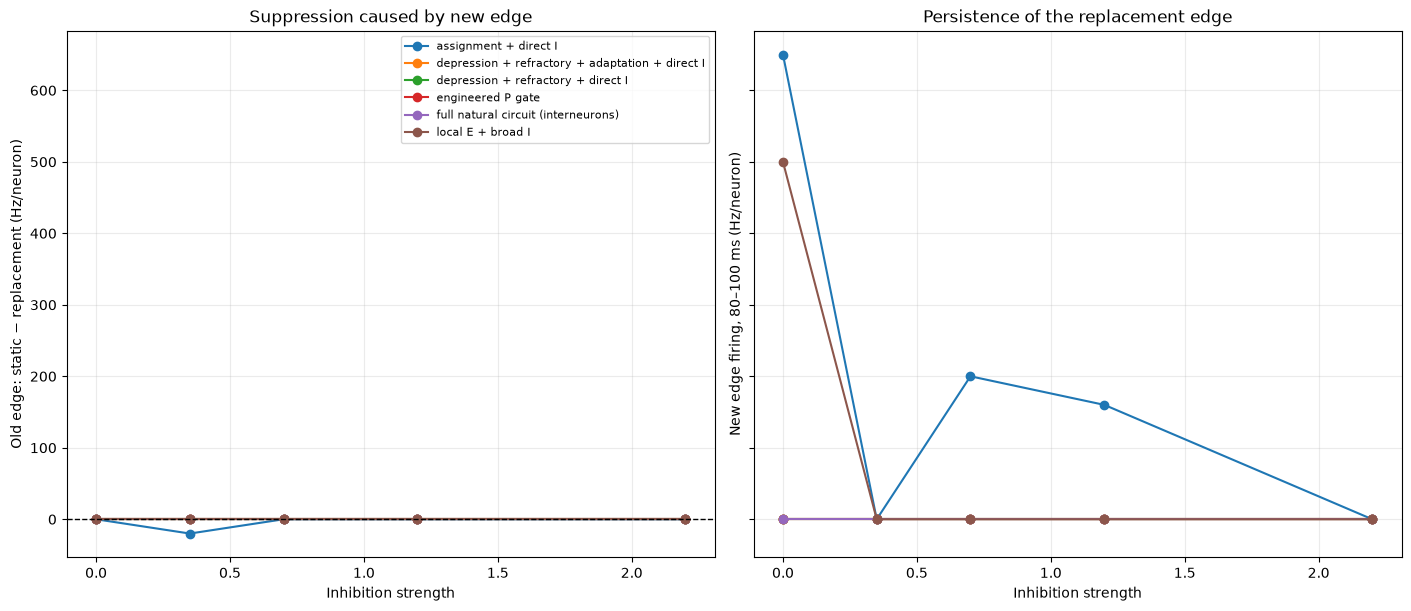

In [5]:
late = measurements.query("start_ms == 80").pivot_table(
    index=["model", "inhibition", "edge"], columns="protocol", values="rate_hz")
old = late.xs("old", level="edge")
new = late.xs("new", level="edge")
summary = pd.DataFrame({
    "old_static_hz": old.static,
    "old_replacement_hz": old.replacement,
    "old_suppression_hz": old.static - old.replacement,
    "new_only_hz": new.new_only,
    "new_replacement_hz": new.replacement,
    "new_interference_hz": new.new_only - new.replacement,
    "old_simultaneous_hz": old.simultaneous,
    "new_simultaneous_hz": new.simultaneous,
}).reset_index()
display(summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True, constrained_layout=True)
for model, group in summary.groupby("model", sort=False):
    axes[0].plot(group.inhibition, group.old_suppression_hz, marker="o", label=model)
    axes[1].plot(group.inhibition, group.new_replacement_hz, marker="o", label=model)
axes[0].axhline(0, linestyle="--", color="black", linewidth=1)
axes[0].set(title="Suppression caused by new edge", xlabel="Inhibition strength",
            ylabel="Old edge: static − replacement (Hz/neuron)")
axes[1].set(title="Persistence of the replacement edge", xlabel="Inhibition strength",
            ylabel="New edge firing, 80–100 ms (Hz/neuron)")
for ax in axes: ax.grid(alpha=0.25)
axes[0].legend(fontsize=8)
plt.show()

## 6. Verify persistence pixel-by-pixel

A mean rate can be dominated by one highly active neuron. We therefore explicitly measure whether **each** edge pixel emits at least two spikes in the late window and whether it fires in both 65–80 and 80–100 ms.

These are operational tests of persistent activity, not arbitrary biological thresholds. The two-spike criterion is stricter than notebook 14's one-spike participation score. We display the raw counts so the interpretation can be revisited without rerunning the simulations.

In [6]:
def edge_counts(run, edge, a, b):
    ids = run["i"][(run["t"] >= a) & (run["t"] < b)]
    return np.bincount(ids, minlength=N)[edge]

persist = []
for model, strength, protocol in runs:
    run = runs[(model, strength, protocol)]
    for edge_name, edge in (("old",old_edge),("new",new_edge)):
        first = edge_counts(run, edge, 65,80)
        last = edge_counts(run, edge, 80,100)
        persist.append(dict(model=model, inhibition=strength, protocol=protocol,
            edge=edge_name, two_plus_last=int(np.sum(last>=2)),
            present_both=int(np.sum((first>0)&(last>0))),
            last_counts=" ".join(map(str,last))))
persistence = pd.DataFrame(persist)
display(persistence.query("protocol == 'replacement' and edge == 'new'").round(2))

# Describe candidates without assigning an unjustified combined performance score.
join = summary.merge(persistence.query("protocol == 'replacement' and edge == 'new'")
    [["model", "inhibition", "two_plus_last", "present_both", "last_counts"]],
    on=["model", "inhibition"])
candidates = join[(join.old_suppression_hz>0) & (join.two_plus_last==5) &
                  (join.present_both==5)]
print(f"Configurations showing old-edge suppression and sustained firing in all five new pixels: {len(candidates)}")
display(candidates.round(2))

,model,inhibition,protocol,edge,two_plus_last,present_both,last_counts
5,assignment + direct I,0.00,replacement,new,5,5,13 13 13 13 13
13,assignment + direct I,0.35,replacement,new,0,0,0 0 0 0 0
21,assignment + direct I,0.70,replacement,new,2,2,10 0 0 0 10
29,assignment + direct I,1.20,replacement,new,2,2,8 0 0 0 8
37,assignment + direct I,2.20,replacement,new,0,0,0 0 0 0 0
45,depression + refractory + direct I,0.00,replacement,new,0,0,0 0 0 0 0
53,depression + refractory + direct I,0.35,replacement,new,0,0,0 0 0 0 0
61,depression + refractory + direct I,0.70,replacement,new,0,0,0 0 0 0 0
69,depression + refractory + direct I,1.20,replacement,new,0,0,0 0 0 0 0
77,depression + refractory + direct I,2.20,replacement,new,0,0,0 0 0 0 0


Configurations showing old-edge suppression and sustained firing in all five new pixels: 0


,model,inhibition,old_static_hz,old_replacement_hz,old_suppression_hz,new_only_hz,new_replacement_hz,new_interference_hz,old_simultaneous_hz,new_simultaneous_hz,two_plus_last,present_both,last_counts


## 7. Spatiotemporal checks and numerical refinement

To avoid interpreting a table without examining the dynamics, plot rasters and per-edge firing rates for one selected candidate (if any), or the best **diagnostic** configuration according to how many new pixels remain active. The diagnostic fallback is **not** declared a winner.

Then repeat representative configurations at dt = 0.1, 0.05, 0.025 ms for the matched **static** and **replacement** protocols. Compare the suppression difference and new-edge firing; decreasing dt alone cannot turn fading into competition.

A convergence result is local to the tested parameters and times; the original ESCM gate and the scheduler-free natural circuits remain different mathematical models.

No fully passing candidate. Diagnostic example: assignment + direct I inhibition 0.0


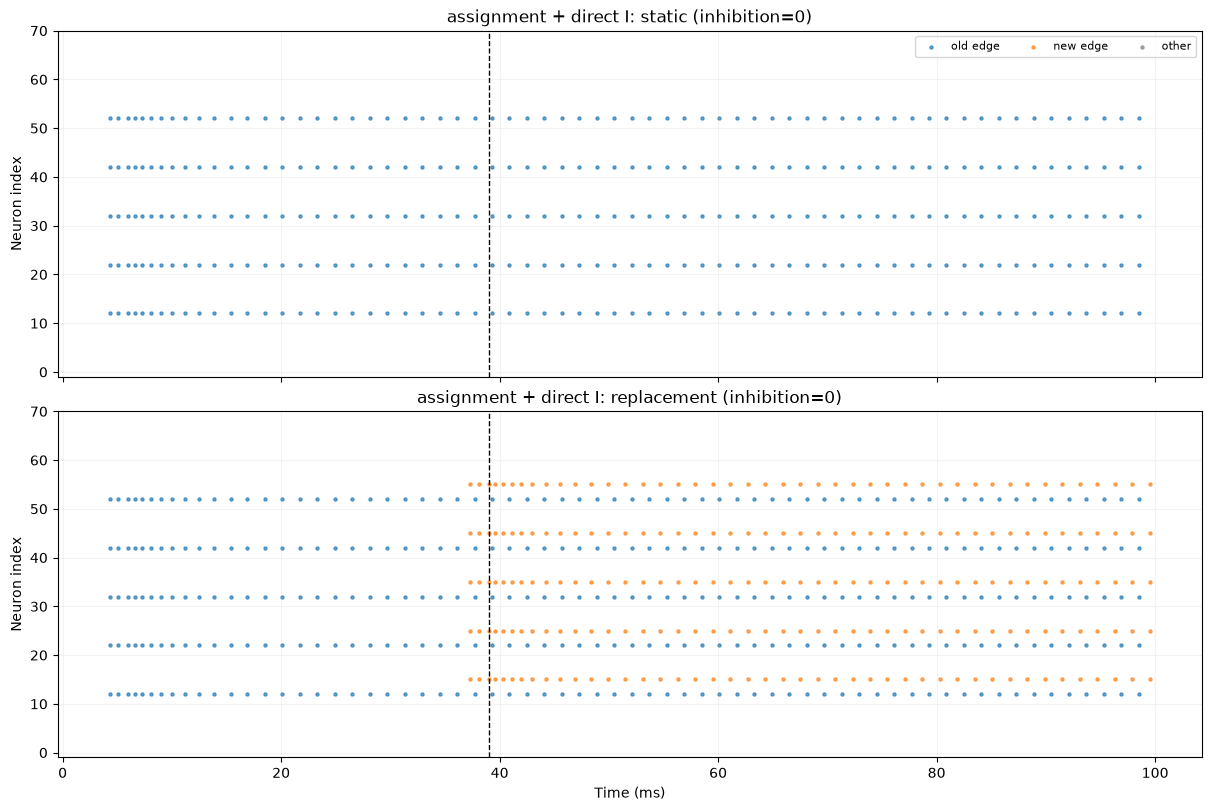

,model,inhibition,dt_ms,old_suppression_hz,new_rate_hz,sustained_new_pixels
0,depression + refractory + direct I,0.70,0.10,0.0,0.0,0
1,depression + refractory + direct I,0.70,0.05,0.0,0.0,0
2,depression + refractory + direct I,0.70,0.02,0.0,0.0,0
3,depression + refractory + adaptation + direct I,0.70,0.10,0.0,0.0,0
4,depression + refractory + adaptation + direct I,0.70,0.05,0.0,0.0,0
5,depression + refractory + adaptation + direct I,0.70,0.02,0.0,0.0,0
6,full natural circuit (interneurons),0.35,0.10,0.0,0.0,0
7,full natural circuit (interneurons),0.35,0.05,0.0,0.0,0
8,full natural circuit (interneurons),0.35,0.02,0.0,0.0,0
9,assignment + direct I,0.70,0.10,0.0,200.0,2


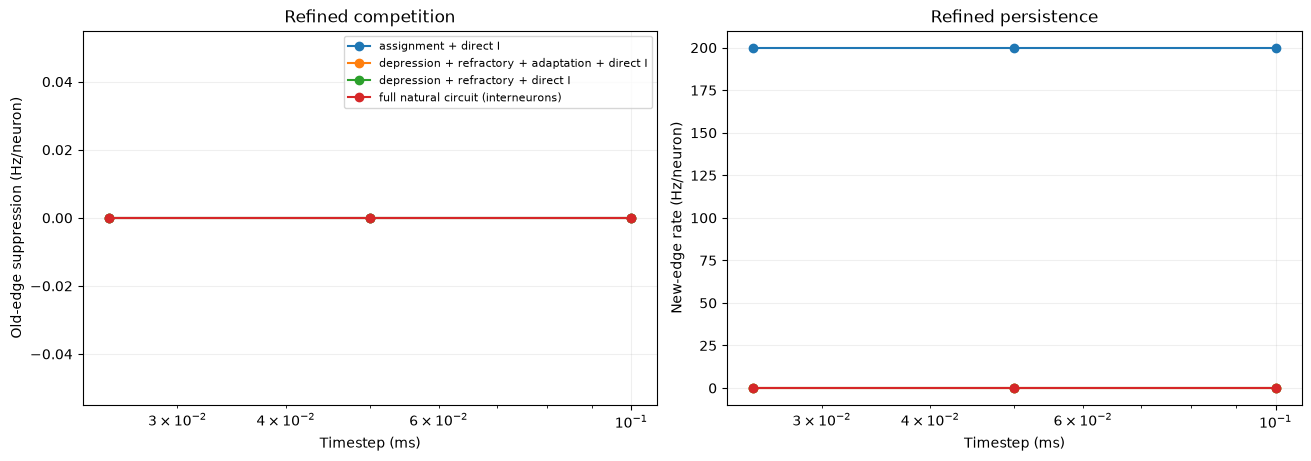

In [7]:
if len(candidates):
    selected = candidates.iloc[0]
    print("Illustrative candidate:", selected.model, "inhibition", selected.inhibition)
else:
    selected = join.sort_values(["present_both", "two_plus_last", "new_replacement_hz"],
                                ascending=False).iloc[0]
    print("No fully passing candidate. Diagnostic example:", selected.model,
          "inhibition", selected.inhibition)
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, protocol in zip(axes, ("static", "replacement")):
    run = runs[(selected.model, selected.inhibition, protocol)]
    for edge, color, label in ((old_edge, "tab:blue", "old edge"),
                               (new_edge, "tab:orange", "new edge"),
                               (other, "0.5", "other")):
        take = np.isin(run["i"], edge)
        ax.scatter(run["t"][take], run["i"][take], s=5, c=color, alpha=0.65,
                   label=label)
    ax.axvline(39, color="black", linestyle="--", linewidth=1,
               label="last new input" if protocol == "replacement" else None)
    ax.set(title=f"{selected.model}: {protocol} (inhibition={selected.inhibition:g})",
           ylabel="Neuron index", ylim=(-1,N))
    ax.grid(alpha=0.15)
axes[0].legend(ncol=3, fontsize=8)
axes[1].set_xlabel("Time (ms)")
plt.show()

refine = []
for model, strength in (("depression + refractory + direct I", 0.7),
                        ("depression + refractory + adaptation + direct I", 0.7),
                        ("full natural circuit (interneurons)", 0.35),
                        ("assignment + direct I", 0.7)):
    for dt_ms in tqdm((0.1, 0.05, 0.025), desc=model, leave=False):
        ctrl = simulate(tested[model], "static", dt_ms,
                        inhibition_strength=strength)
        repl = simulate(tested[model], "replacement", dt_ms,
                        inhibition_strength=strength)
        r_old_ctrl = edge_metrics(ctrl, old_edge, 80,100)["rate_hz"]
        r_old_repl = edge_metrics(repl, old_edge, 80,100)["rate_hz"]
        r_new_repl = edge_metrics(repl, new_edge, 80,100)["rate_hz"]
        refine.append(dict(model=model, inhibition=strength, dt_ms=dt_ms,
                          old_suppression_hz=r_old_ctrl-r_old_repl,
                          new_rate_hz=r_new_repl,
                          sustained_new_pixels=np.sum(edge_counts(repl,new_edge,80,100)>=2)))
refinement = pd.DataFrame(refine)
display(refinement.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13,4.5), constrained_layout=True)
for model, group in refinement.groupby("model"):
    axes[0].plot(group.dt_ms,group.old_suppression_hz,"o-",label=model)
    axes[1].plot(group.dt_ms,group.new_rate_hz,"o-",label=model)
for ax in axes:
    ax.set(xscale="log", xlabel="Timestep (ms)")
    ax.grid(alpha=0.2)
axes[0].set(ylabel="Old-edge suppression (Hz/neuron)",title="Refined competition")
axes[1].set(ylabel="New-edge rate (Hz/neuron)",title="Refined persistence")
axes[0].legend(fontsize=8)
plt.show()

## 8. Interpretation and limitations

**Evidence for actual replacement requires all of:** (i) old-edge persistent spiking without the second input, (ii) less old-edge spiking after the second input, and (iii) sustained spiking throughout the new edge long after input stops. Even if those conditions hold, the two edges' relative order and inhibition strengths should be tested beyond this demonstration.

A depressed circuit that produces one spike per new pixel but no late activity **does not pass**. Nor does a circuit where both static and replacement conditions have zero late activity; that is natural fading, not competitive suppression.

This notebook uses a common simulation model carried forward from Notebook 14. It does **not** independently audit all new nonlinear synaptic rules against a separate NumPy reference. Parameter ranges are illustrative; no physiological calibration or universal stability claim is made. The explicit inhibitory-interneuron models should be compared at fixed recruitment gain (12 here); a subsequent experiment may vary recruitment independently if the 0.35–2.2 inhibition sweep does not reveal a useful regime.